In [57]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import parallel_config
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TARGETS = ["country", "province", "region_1"]
MIN_TRAIN_REVIEWS = 0
N_JOBS = 6 #change depending on number of cores
BLUE = "#2a78d6"
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

In [58]:
df = pd.read_parquet("data_clean/wine_reviews_clean.parquet")
df

,country,description,designation,points,price,province,region_1,region_2,taster_name,title,variety,winery,vintage,log_price,price_missing,country_group
0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia,2013,NaN,True,Italy
1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos,2011,2.708050,False,Portugal
2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm,2013,2.639057,False,US
3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian,2013,2.564949,False,US
4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks,2012,4.174387,False,US
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119917,Germany,Notes of honeysuckle and cantaloupe sweeten th...,Brauneberger Juffer-Sonnenuhr Spätlese,90,28.0,Mosel,NaN,NaN,Anna Lee C. Iijima,Dr. H. Thanisch (Erben Müller-Burggraef) 2013 ...,Riesling,Dr. H. Thanisch (Erben Müller-Burggraef),2013,3.332205,False,Germany
119918,US,Citation is given as much as a decade of bottl...,NaN,90,75.0,Oregon,Oregon,Oregon Other,Paul Gregutt,Citation 2004 Pinot Noir (Oregon),Pinot Noir,Citation,2004,4.317488,False,US
119919,France,Well-drained gravel soil gives this wine its c...,Kritt,90,30.0,Alsace,Alsace,NaN,Roger Voss,Domaine Gresser 2013 Kritt Gewurztraminer (Als...,Gewürztraminer,Domaine Gresser,2013,3.401197,False,France
119920,France,"A dry style of Pinot Gris, this is crisp with ...",NaN,90,32.0,Alsace,Alsace,NaN,Roger Voss,Domaine Marcel Deiss 2012 Pinot Gris (Alsace),Pinot Gris,Domaine Marcel Deiss,2012,3.465736,False,France


In [59]:
df = df[df["taster_name"] == "Anne Krebiehl MW"]

In [60]:
strata = df["country_group"].fillna("Unknown")
train, rest = train_test_split(df, test_size=0.3, stratify=strata, random_state=SEED)
val, test = train_test_split(rest, test_size=0.5, stratify=strata[rest.index], random_state=SEED)
len(train), len(val), len(test)

(2301, 493, 494)

In [61]:
pd.DataFrame({name: split["country"].value_counts(normalize=True).head(8) * 100 for name, split in
              [("train", train), ("val", val), ("test", test)]}).round(1)

,train,val,test
country,,,
Austria,59.8,59.9,59.6
France,38.3,38.3,38.3
England,1.9,1.8,2.0


In [63]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True, max_features=20000)
X_train = vectorizer.fit_transform(train["description"])
X_val = vectorizer.transform(val["description"])
X_test = vectorizer.transform(test["description"])
X_train.shape

(2301, 4927)

In [64]:
keep = {}
summary = []
for target in TARGETS:
    counts = train[target].value_counts()
    keep[target] = counts[counts >= MIN_TRAIN_REVIEWS].index
    summary.append({
        "target": target,
        "all_classes": train[target].nunique(),
        "kept_classes": len(keep[target]),
        "pct_missing": train[target].isna().mean() * 100,
        "pct_rows_kept": train[target].isin(keep[target]).mean() * 100,
    })
pd.DataFrame(summary).set_index("target").round(1)

,all_classes,kept_classes,pct_missing,pct_rows_kept
target,,,,
country,3,3,0.2,99.8
province,27,27,0.2,99.8
region_1,2,2,61.8,38.2


In [65]:
def subset(split, X, target):
    mask = split[target].isin(keep[target]).to_numpy()
    return X[mask], split[target].to_numpy()[mask]

In [66]:
def make_models():
    return {
        "Most frequent (dummy)": DummyClassifier(strategy="most_frequent"),
        "Logistic regression": OneVsRestClassifier(LogisticRegression(C=10, solver="liblinear"), n_jobs=N_JOBS),
        "Decision tree": DecisionTreeClassifier(max_depth=30, min_samples_leaf=5, random_state=SEED),
    }

In [67]:
fitted = {}
results = []
for target in TARGETS:
    Xt, yt = subset(train, X_train, target)
    Xv, yv = subset(val, X_val, target)
    for name, model in make_models().items():
        start = time.perf_counter()
        with parallel_config(max_nbytes=None):
            model.fit(Xt, yt)
        fit_seconds = time.perf_counter() - start
        pred = model.predict(Xv)
        fitted[target, name] = model
        results.append({
            "target": target,
            "model": name,
            "train_accuracy": accuracy_score(yt, model.predict(Xt)),
            "accuracy": accuracy_score(yv, pred),
            "macro_F1": f1_score(yv, pred, average="macro", zero_division=0),
            "fit_seconds": fit_seconds,
        })
results = pd.DataFrame(results).set_index(["target", "model"])
results.round(3)

train_accuracy  accuracy  macro_F1  \
target   model                                                       
country  Most frequent (dummy)           0.598     0.599     0.250   
         Logistic regression             0.998     0.851     0.566   
         Decision tree                   0.904     0.776     0.556   
province Most frequent (dummy)           0.383     0.383     0.024   
         Logistic regression             0.998     0.509     0.119   
         Decision tree                   0.647     0.401     0.083   
region_1 Most frequent (dummy)           0.875     0.856     0.461   
         Logistic regression             1.000     0.920     0.785   
         Decision tree                   0.970     0.941     0.861   

                                fit_seconds  
target   model                               
country  Most frequent (dummy)        0.000  
         Logistic regression          1.385  
         Decision tree                0.143  
province Most frequent (dummy)        0.000  
         Logistic regression          1.003  
         Decision tree                0.142  
region_1 Most frequent (dummy)        0.000  
         Logistic regression          0.014  
         Decision tree                0.023

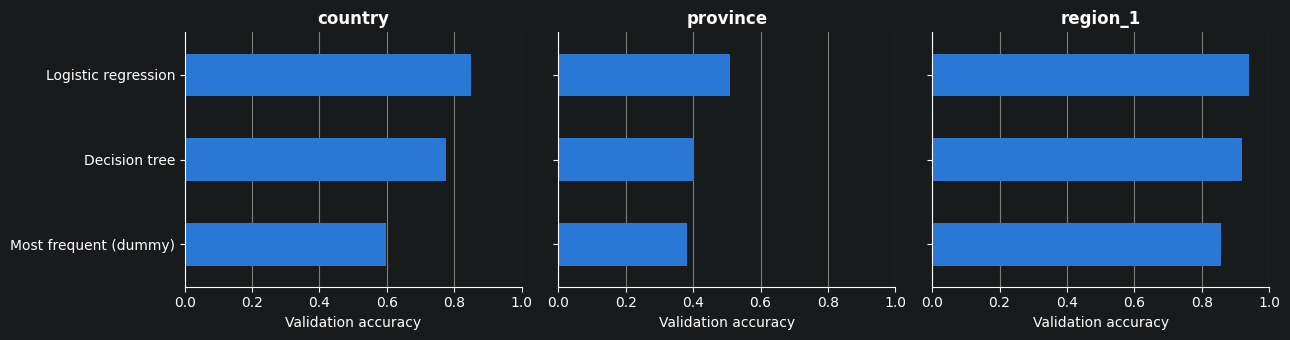

In [68]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(13, 3.5), sharex=True)
for ax, target in zip(axes, TARGETS):
    results.loc[target, "accuracy"].sort_values().plot.barh(color=BLUE, ax=ax)
    ax.set(title=target, xlabel="Validation accuracy", ylabel="", xlim=(0, 1))
    ax.grid(axis="y", visible=False)
for ax in axes[1:]:
    ax.tick_params(labelleft=False)
plt.tight_layout()

In [69]:
logreg = fitted["country", "Logistic regression"]
words = vectorizer.get_feature_names_out()
coefs = np.vstack([
    estimator.coef_[0]
    for estimator in logreg.estimators_
])
top_words = {
    country: words[np.argsort(country_coef)[::-1][:8]]
    for country, country_coef in zip(logreg.classes_, coefs)
}
pd.DataFrame(top_words).T

,0,1,2,3,4,5,6,7
Austria,slender,grüner,spritz,zesty,savory,white,yeast,green
England,tart,apple,crisp,mousse,autolysis,bubbles,creamy,tiny
France,dry,apple,peach,the dry,dry and,residual,sweet,is dry
